# Phasing HERA UVData to satellites as they cross the beam

`find_satellites/run_pipeline.py` finds, for a given night and constellation, every timestamp at which a satellite is inside HERA's field of view (FOV) - a 10°-wide disk centred on zenith - and which moment has the most satellites in the beam at once. This notebook takes that output one step further: it phases actual HERA `UVData` to the satellite(s) crossing the beam, using [`UVData.phase(..., cat_type="ephem")`](https://pyuvdata.readthedocs.io/en/latest/uvdata.html#pyuvdata.UVData.phase) ie pyuvdata's phase-center type for a target whose RA/Dec moves with time.

**Why not a single, fixed-RA/Dec `phase()` call?** HERA is a drift-scan telescope - its raw/'sum' files are phased to zenith, not to any fixed sky position. A LEO satellite can sweep several degrees across the sky in the ~20 s it takes to cross the FOV, so one fixed RA/Dec is only right for an instant. `cat_type="ephem"` instead takes the source's RA/Dec at a handful of times (`ephem_times`, in JD) and pyuvdata interpolates the apparent position to every timestamp being phased.

**Where the RA/Dec(t) ephemeris comes from:** `run_pipeline.py`'s `find_fov_passes.py` step already re-propagates every satellite's TLE with SGP4 and records every in-beam timestamp (`<SAT>_results.csv`, with the TLE itself saved as a comment header). `phase_data/phase_to_satellites.py` (loaded below) re-propagates that same TLE at the exact timestamps present in the `UVData` object - not `find_fov_passes.py`'s fixed sampling grid, which in general won't align with the correlator's own integration times - and converts the result to ICRS RA/Dec for `phase()`.

This demo builds a *synthetic* `UVData` object over the busiest window using the real telescope metadata (antenna layout, location) and everything downstream is identical to what you'd do with real files for the night; see the note in Step 3.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from astropy import units
from astropy.time import Time
from astropy.coordinates import AltAz, ICRS, SkyCoord
from pyuvdata import UVData, Telescope

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "phase_data" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "phase_data"))
sys.path.insert(0, str(REPO_ROOT / "find_satellites"))

import phase_to_satellites as pts
from parameters import fov_angular_radius, position_angles, hera_location
from utils import plot_waterfall  # find_satellites/utils.py

## Step 1: find the busiest night/moment from `run_pipeline.py`'s output

Point `PIPELINE_RUN_DIR` at any completed `run_pipeline.py` run (e.g., `python run_pipeline.py --date <date> --constellation Starlink`, see `find_satellites/README.md`). Here we use the Orbcomm run for 2022-10-23.

In [2]:
PIPELINE_RUN_DIR = REPO_ROOT / "find_satellites" / "orbcomm_2022-10-23"
FOV_DIR = PIPELINE_RUN_DIR / "fov_passes"

print((PIPELINE_RUN_DIR / "pipeline_summary.txt").read_text())

Pipeline run: Orbcomm, night of 2022-10-23

Night considered:    2022-10-23 16:46:35.000 to 2022-10-24 03:50:10.000 UTC (Sun below horizon at HERA)
TLE file:            orbcomm_2022-10-23/tle/2022-10-23_orbcomm_tles.txt
FOV-pass CSVs:       orbcomm_2022-10-23/fov_passes/*_results.csv
Busiest moment:      2022-10-23 21:10:15.000 UTC (1/61 satellites in beam)
Plot window:         2022-10-23T21:02:45.000 to 2022-10-23T21:17:45.000 UTC (15 min)
Trajectory plot:     orbcomm_2022-10-23/beam_busiest_window.png



The busiest moment that night was **2022-10-23 21:10:15 UTC**, with 1/61 Orbcomm satellites in the beam. Grepping the FOV-pass CSVs for that timestamp identifies the satellite: **ORBCOMM FM 27**, transiting almost exactly through zenith.

In [3]:
import subprocess
print(subprocess.run(
    ["grep", "-l", "2022-10-23 21:10:15.000", *[str(p) for p in FOV_DIR.glob("*_results.csv")]],
    capture_output=True, text=True,
).stdout)

/Users/adeliegorce/Library/CloudStorage/OneDrive-McGillUniversity/Research/HERA/Satellite constellations/find_satellites/orbcomm_2022-10-23/fov_passes/ORBCOMM_FM_27_results.csv



## Step 2: real telescope metadata

Read the one real HERA file available locally, `zen.2459876.44074.sum.uvh5` - just for its antenna layout and location (`read_data=False`, so the ~745 MB visibility array itself isn't loaded). It only covers ~10 s on this same night (22:34:35-45 UTC), which doesn't overlap any satellite's FOV crossing - `satellites_in_time_range` correctly returns nothing for it.

In [4]:
telescope = Telescope.from_known_telescopes('HERA')
telescope.instrument = telescope.name  # from_known_telescopes() leaves this unset, but UVData.new() requires it
print(f"{telescope.Nants} antennas, location {telescope.location}")

350 antennas, location (5109325.855210627, 2005235.0914298263, -3239928.424753935) m


## Step 3: build a `UVData` object spanning the busiest window

**With real data for this night**, this step is just `uv = UVData(); uv.read(["zen.2459876.XXXXX.sum.uvh5", ...])` for whichever files cover the busiest window - skip straight to Step 4.

Without a full night on hand, we instead synthesize one with [`UVData.new()`](https://pyuvdata.readthedocs.io/en/latest/uvdata.html#pyuvdata.UVData.new), reusing the *real* telescope object from Step 2 (so the array geometry/location is genuine) but with:
- a made-up handful of baselines (4 antennas → 6 baselines) instead of all 350 antennas, to keep this notebook fast,
- ~10 frequency channels near 137.5 MHz (Orbcomm's VHF downlink band, and within HERA's 47-234 MHz range), at HERA's real ~122 kHz channel width, instead of the full 1536-channel band,
- a 5 s cadence (matching `find_fov_passes.py`'s own `--day` sampling, chosen there for the same reason: fine enough not to step over a pass as short as ~20 s),
- `empty=True`, so `data_array`/`flag_array`/`nsample_array` are all zeroed - a stand-in for real correlator output; only the metadata (times, antenna pairs, phase centers) is genuine here.

In [5]:
antnums = telescope.antenna_numbers[:4]
antpairs = [(a, b) for i, a in enumerate(antnums) for b in antnums[i + 1:]]

t0 = Time("2022-10-23T21:08:00", scale="utc")
times = t0 + np.arange(0, 271, 5) * units.s  # 5 s cadence, ~4.5 min window

# 10 channels at HERA's real ~122 kHz channel width, centred near
# 137.5 MHz (Orbcomm's VHF downlink band, within HERA's 47-234 MHz range) -
# just enough channels for a quick demo, not the full 1536-channel band.
channel_width = 122070.3125
freq_array = 137.5e6 + channel_width * np.arange(-5, 5)

uv = UVData.new(
    freq_array=freq_array,
    polarization_array=[-5],
    times=times.jd,
    telescope=telescope,
    antpairs=antpairs,
    do_blt_outer=True,
    integration_time=5.0,
    channel_width=channel_width,
    empty=True,
)
print(f"{uv.Ntimes} times x {uv.Nbls} baselines x {uv.Nfreqs} freq channels")
print(f"{times[0].iso} to {times[-1].iso}")
print("Initial phase center:", uv.phase_center_catalog)

55 times x 6 baselines x 10 freq channels
2022-10-23 21:08:00.000 to 2022-10-23 21:12:30.000
Initial phase center: {0: {'cat_name': 'unprojected', 'cat_type': 'unprojected', 'cat_lon': 0.0, 'cat_lat': 1.5707963267948966, 'cat_frame': 'altaz', 'cat_epoch': None, 'cat_times': None, 'cat_pm_ra': None, 'cat_pm_dec': None, 'cat_vrad': None, 'cat_dist': None, 'info_source': 'user'}}


## Step 4: phase to every satellite pass in this window

`phase_uvdata_to_all_passes()`:
1. Uses `satellites_in_time_range()` as a fast pre-filter over `FOV_DIR`'s CSVs (so, for a big constellation like Starlink, only satellites actually near this window get re-propagated - not the whole TLE file).
2. For each candidate, re-propagates its TLE with SGP4 at `uv`'s own exact timestamps (`phase_uvdata_to_satellite()`), converts to ICRS RA/Dec, and calls `uv.select(blt_inds=...)` + `uv.phase(cat_type="ephem", ...)` - returning one `UVData` copy per satellite, restricted to just the baseline-times it was actually in the beam.

One copy per satellite (rather than one shared object) because a `UVData`'s `phase_center_id_array` assigns exactly one phase center per baseline-time - two satellites simultaneously in the beam can't both be "the" phase center of the same object at the same time.

In [6]:
phased_uv = pts.phase_uvdata_to_all_passes(uv, FOV_DIR)
phased_uv

Phased to ORBCOMM FM 27: 4 time sample(s), 2022-10-23 21:10:15.000 to 2022-10-23 21:10:30.000


{'ORBCOMM FM 27': <pyuvdata.uvdata.uvdata.UVData at 0x16f50c910>}

In [7]:
sat_name, uv_sat = next(iter(phased_uv.items()))
uv_sat.phase_center_catalog

{1: {'cat_name': 'ORBCOMM FM 27',
  'cat_type': 'ephem',
  'cat_lon': array([0.12867839, 0.17001341, 0.21276032, 0.25686146]),
  'cat_lat': array([-0.5112021 , -0.53892048, -0.56588781, -0.5919391 ]),
  'cat_frame': 'icrs',
  'cat_epoch': 2000.0,
  'cat_times': array([2459876.38211806, 2459876.38217593, 2459876.3822338 ,
         2459876.38229167]),
  'cat_pm_ra': None,
  'cat_pm_dec': None,
  'cat_vrad': None,
  'cat_dist': None,
  'info_source': 'user'}}

## Step 5: sanity-check plot

The phase center's recovered *apparent* RA/Dec (`uv_sat.phase_center_app_ra/dec` - what pyuvdata actually uses to compute `uvw_array`) should sit right on top of HERA's FOV disk at zenith, in the same style of plot `find_satellites/beam_vs_starlink.py` and `test_orbcomm_14.py` already use elsewhere in this repo.

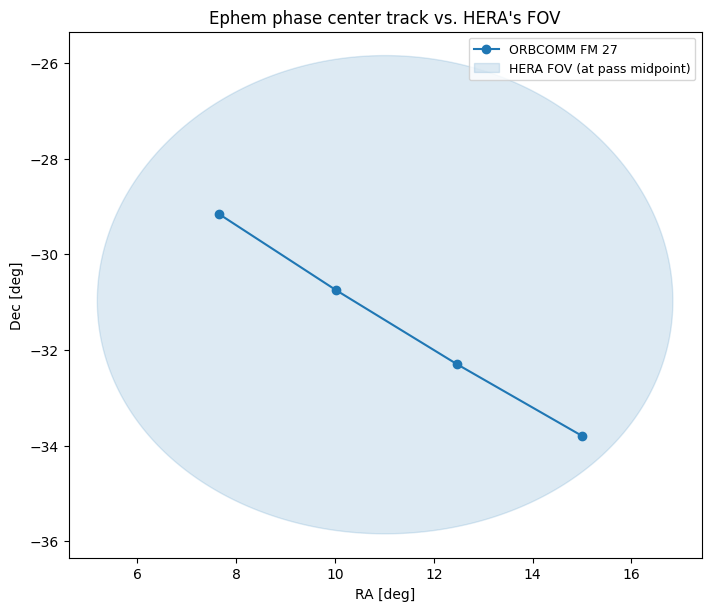

In [8]:
fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)

for i, (sat_name, uv_sat) in enumerate(phased_uv.items()):
    unique_t, idx = np.unique(uv_sat.time_array, return_index=True)
    ra = np.degrees(uv_sat.phase_center_app_ra[idx])
    dec = np.degrees(uv_sat.phase_center_app_dec[idx])
    ax.plot(ra, dec, "o-", label=sat_name)

    # FOV disk outline at the pass's midpoint.
    mid = Time(unique_t[len(unique_t) // 2], format="jd", scale="utc")
    zenith = SkyCoord(
        AltAz(alt=90 * units.deg, az=0 * units.deg, obstime=mid, location=hera_location)
    ).transform_to(ICRS())
    ring = zenith.directional_offset_by(position_angles, fov_angular_radius)
    ax.fill(
        ring.ra.wrap_at(360 * units.deg).deg, ring.dec.deg,
        alpha=0.15, color="C0",
        label="HERA FOV (at pass midpoint)" if i == 0 else None,
    )

ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_title("Ephem phase center track vs. HERA's FOV")
ax.legend(fontsize=9, loc="upper right")
# fig.savefig("phase_center_vs_fov.png", dpi=150)

## Step 6: waterfall plot, shaded by FOV membership

`phase_uvdata_to_satellite(..., in_beam_only=False)` phases the satellite across `uv`'s *entire* time range instead of just the samples it was inside the FOV for - useful for looking at behaviour before/after the transit (e.g. far-sidelobe contamination). `find_satellites/utils.py`'s new `plot_waterfall()` plots the resulting time-vs-frequency amplitude for one baseline, hatching the times the satellite was actually inside the FOV.

That hatching comes from `utils.in_beam_mask()`, which reads the shading straight off `uv`'s own `phase_center_catalog` (transforming its stored ephemeris back to AltAz) - it doesn't need the TLE or `fov_dir` again, so it works on *any* phased `UVData`, not just ones built by `phase_to_satellites.py`.

55 times (full window, vs. 4 in-beam only)


Text(0.5, 1.0, 'ORBCOMM FM 27 - phased, full window')

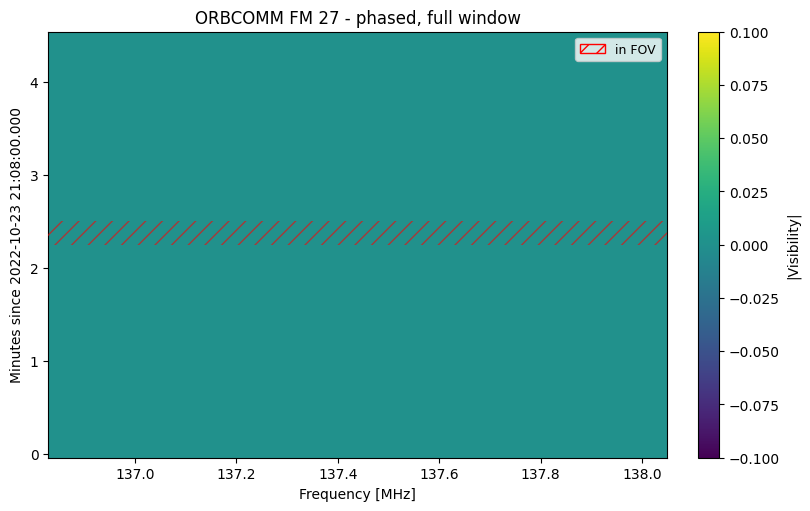

In [9]:
t_start = Time(uv.time_array.min(), format="jd", scale="utc")
t_end = Time(uv.time_array.max(), format="jd", scale="utc")
tle_line1, tle_line2 = pts.satellites_in_time_range(FOV_DIR, t_start, t_end)[sat_name]

uv_sat_full = pts.phase_uvdata_to_satellite(
    uv, sat_name, tle_line1, tle_line2, in_beam_only=False,
)
print(f"{uv_sat_full.Ntimes} times (full window, vs. {uv_sat.Ntimes} in-beam only)")

ax = plot_waterfall(uv_sat_full, hera_location, fov_angular_radius)
ax.set_title(f"{sat_name} - phased, full window")

## Caveats worth knowing before using this on real data

**Distance/parallax is deliberately dropped, not an oversight.** `phase_to_satellites.satellite_ephemeris()` converts each AltAz sample to ICRS *without* keeping the satellite's true range - it only keeps the alt/az *direction*. Keeping the true range (a few hundred to ~2000 km) makes astropy apply diurnal parallax appropriate to Earth's radius (~6371 km, much larger than the satellite's own range), which wildly overcorrects: the resulting RA/Dec barely moves across a pass even though the satellite visibly sweeps the sky (this was verified numerically while building this module - it's *the* easy way to get this silently wrong). Separately, pyuvdata's own `cat_type="ephem"` apparent-coordinate pipeline doesn't apply a distance/parallax correction either (a documented `TODO` in `pyuvdata.utils.phasing` as of pyuvdata 3.2.1) - so the plain topocentric apparent direction is exactly what it expects here.

**Far-field phasing is still the right approximation for the *array* itself.** Treating the satellite as a plane wave across HERA's baselines (rather than a genuinely nearby point requiring `cat_type="near_field"`) introduces a near-field defocus of order $B^2/2D$ in path length - for $B \approx 300$ m and $D \approx 700$ km, that's about 6 cm ($\sim$0.2 ns of delay), far below HERA's $\sim$120 kHz channel resolution ($\sim$8 $\mu$s). `near_field` also only accepts a single fixed lon/lat/dist per call, so tracking a moving near-field source with it means calling `phase()` once per timestamp instead of supplying an ephemeris.

**Multiple satellites overlapping in time** each get their own `UVData` copy (see Step 4) rather than sharing one multi-phase-center object, since a baseline-time can only have one active phase center at once.

**For downstream analysis** (e.g. looking for the satellite's own RFI signature): with real correlator data in place of the synthetic zeros here, a correctly-phased satellite should show up as slowly-varying/coherent visibility at its phase center, versus the fast fringe rotation the same samples would show if left phased to zenith.